# Day 046 | K-Means Clustering

## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  
**Date:** YYYY-MM-DD  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Unsupervised learning | No labels — discover patterns | Grouping soil samples without pre-defined classes |
| K-Means clustering | Partition data into K groups | Identify K distinct soil types from properties |
| Centroids | Center of each cluster | Average properties of each soil group |
| Inertia | Sum of distances to nearest centroid | How tight the clusters are |
| Elbow method | Find optimal K by inertia plot | How many distinct soil groups exist? |
| Silhouette score | Measure cluster quality | Are the soil groups well-separated? |
| PCA visualization | Project high-D data to 2D | See clusters on a flat plot |
| Cluster interpretation | Label clusters by properties | Name discovered soil groups |

---

## Our Geotechnical Problem

**Automatic Soil Classification from Lab/Field Data**

A site investigation produces hundreds of soil samples with measured properties (N-value, water content, fines, void ratio, unit weight). Engineers manually group these into soil types — but can we do it automatically?

**K-Means clustering** finds natural groupings in the data without any labels. This is **unsupervised learning** — no teacher telling the algorithm what the groups are.

Applications:
- Automatic soil stratification from CPT/SPT data
- Identifying anomalous zones in a site
- Grouping similar boreholes for design zonation

---

## Part 1: How K-Means Works (Step by Step)

The K-Means algorithm is beautifully simple:

1. **Choose K** (number of clusters)
2. **Initialize** K random centroids
3. **Assign** each point to its nearest centroid
4. **Update** each centroid to the mean of its assigned points
5. **Repeat** steps 3-4 until centroids stop moving

```
Step 1: Random centroids    Step 2: Assign points    Step 3: Update centroids
    x   o                    x---o                    x  o
  x   x   o   o           x---x   o---o             [X]  [O]
    x     o   o              x   o---o---o              x   o  o
  x   x     o              x---x     o                x x    o
          ↑ ↑                                        ↑    ↑
     random centroids                            new centroids = means
```

The algorithm converges when assignments no longer change.

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS AND SETUP
# ─────────────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples

np.random.seed(46)
print("Libraries loaded successfully.")
print("Today: K-Means clustering for automatic soil classification.")

Libraries loaded successfully.
Today: K-Means clustering for automatic soil classification.


---

## Part 2: Generate Synthetic Soil Sample Data

We create 100 soil samples with 5 properties. The samples come from 4 hidden soil groups (which K-Means will try to rediscover).

In [2]:
# ─────────────────────────────────────────────────────
# GENERATE SYNTHETIC SOIL DATA (100 samples, 4 hidden groups)
# ─────────────────────────────────────────────────────

# Group 1: Dense Sand (high N, low water content, low fines)
g1 = np.column_stack([
    np.random.normal(32, 4, 25),   # N_value
    np.random.normal(12, 3, 25),   # water_content
    np.random.normal(8, 3, 25),    # fines_content
    np.random.normal(0.45, 0.05, 25),  # void_ratio
    np.random.normal(19.5, 0.8, 25),   # unit_weight
])

# Group 2: Loose Silty Sand (medium N, medium water, medium fines)
g2 = np.column_stack([
    np.random.normal(12, 3, 25),
    np.random.normal(22, 4, 25),
    np.random.normal(28, 5, 25),
    np.random.normal(0.65, 0.06, 25),
    np.random.normal(17.5, 0.7, 25),
])

# Group 3: Soft Clay (low N, high water content, high fines)
g3 = np.column_stack([
    np.random.normal(4, 2, 25),
    np.random.normal(42, 6, 25),
    np.random.normal(75, 8, 25),
    np.random.normal(1.1, 0.12, 25),
    np.random.normal(15.5, 0.6, 25),
])

# Group 4: Stiff Clay (medium N, high water, high fines)
g4 = np.column_stack([
    np.random.normal(18, 4, 25),
    np.random.normal(30, 5, 25),
    np.random.normal(62, 7, 25),
    np.random.normal(0.78, 0.08, 25),
    np.random.normal(17.0, 0.7, 25),
])

data = np.vstack([g1, g2, g3, g4])
data = np.clip(data, 0, None)  # No negative values

# True labels (for validation only — K-Means will NOT see these)
true_labels = np.array([0]*25 + [1]*25 + [2]*25 + [3]*25)
true_names = {0: 'Dense Sand', 1: 'Loose Silty Sand', 2: 'Soft Clay', 3: 'Stiff Clay'}

df = pd.DataFrame(data, columns=['N_value', 'water_content', 'fines_content',
                                  'void_ratio', 'unit_weight'])
df = df.round(2)

# Shuffle
shuffle_idx = np.random.permutation(100)
df = df.iloc[shuffle_idx].reset_index(drop=True)
true_labels = true_labels[shuffle_idx]

# Save
df.to_csv('soil_samples.csv', index=False)

print(f"Dataset: {df.shape[0]} samples, {df.shape[1]} features")
print(f"\nFeature statistics:")
print(df.describe().round(2).to_string())
print("\nNote: K-Means will NOT see the true group labels.")

Dataset: 100 samples, 5 features

Feature statistics:
       N_value  water_content  fines_content  void_ratio  unit_weight
count   100.00         100.00         100.00      100.00       100.00
mean     16.22          26.63          44.08        0.77        17.27
std      10.92          12.12          27.86        0.27         1.64
min       0.00           3.92           2.23        0.35        14.62
25%       6.82          16.63          16.80        0.54        15.92
50%      14.27          26.22          47.87        0.72        17.08
75%      25.86          35.35          68.49        0.95        18.26
max      38.50          53.73         108.62        1.43        21.16

Note: K-Means will NOT see the true group labels.


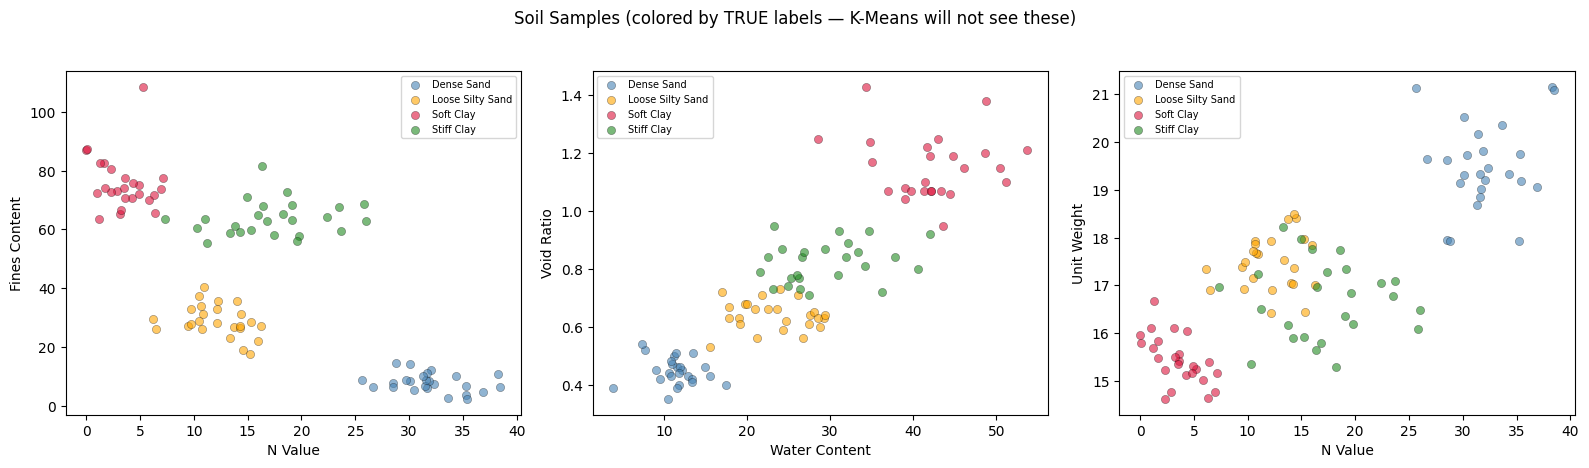

We can see 4 natural groups. K-Means will try to find them without labels.


In [3]:
# ─────────────────────────────────────────────────────
# PAIRPLOT — Visualize features pairwise
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

pairs = [('N_value', 'fines_content'),
         ('water_content', 'void_ratio'),
         ('N_value', 'unit_weight')]

true_colors = ['steelblue', 'orange', 'crimson', 'forestgreen']

for ax, (f1, f2) in zip(axes, pairs):
    for g in range(4):
        mask = true_labels == g
        ax.scatter(df[f1][mask], df[f2][mask], c=true_colors[g],
                   alpha=0.6, edgecolors='k', linewidth=0.3, s=35,
                   label=true_names[g])
    ax.set_xlabel(f1.replace('_', ' ').title())
    ax.set_ylabel(f2.replace('_', ' ').title())
    ax.legend(fontsize=7)

plt.suptitle('Soil Samples (colored by TRUE labels — K-Means will not see these)', fontsize=12, y=1.03)
plt.tight_layout()
plt.show()
print("We can see 4 natural groups. K-Means will try to find them without labels.")

---

## Part 3: Feature Scaling for K-Means

Like SVM, K-Means uses **distances**. Features with larger scales dominate the distance calculation. We must scale before clustering.

In [4]:
# ─────────────────────────────────────────────────────
# SCALE FEATURES
# ─────────────────────────────────────────────────────

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print("Feature scaling comparison:")
print(f"\n{'Feature':<18} {'Original Range':>18} {'Scaled Range':>18}")
print("─" * 56)
for i, col in enumerate(df.columns):
    orig = f"{df[col].min():.1f} — {df[col].max():.1f}"
    scaled = f"{X_scaled[:, i].min():.2f} — {X_scaled[:, i].max():.2f}"
    print(f"{col:<18} {orig:>18} {scaled:>18}")

print("\nWithout scaling, fines_content (0–90) would dominate over void_ratio (0.3–1.4).")

Feature scaling comparison:

Feature                Original Range       Scaled Range
────────────────────────────────────────────────────────
N_value                    0.0 — 38.5       -1.49 — 2.05
water_content              3.9 — 53.7       -1.88 — 2.25
fines_content             2.2 — 108.6       -1.51 — 2.33
void_ratio                  0.3 — 1.4       -1.54 — 2.47
unit_weight               14.6 — 21.2       -1.62 — 2.38

Without scaling, fines_content (0–90) would dominate over void_ratio (0.3–1.4).


---

## Part 4: The Elbow Method — Choosing K

The hardest part of K-Means is choosing **how many clusters**. The **elbow method** plots inertia (within-cluster sum of squares) vs K. Look for the "elbow" where adding more clusters gives diminishing returns.

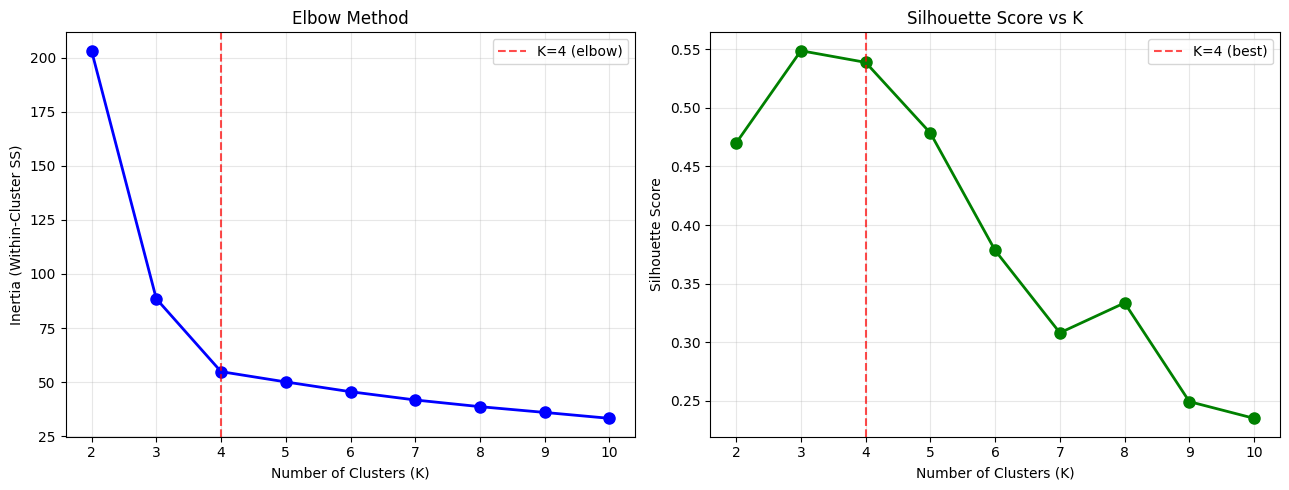

Elbow Method: Inertia drops sharply until K=4, then levels off.
Silhouette Score: Peaks at K=4 (higher = better separation).
Both methods agree: K=4 is the best choice!


In [5]:
# ─────────────────────────────────────────────────────
# ELBOW METHOD
# ─────────────────────────────────────────────────────

K_range = range(2, 11)
inertias = []
sil_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=46)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Elbow plot
axes[0].plot(K_range, inertias, 'b-o', linewidth=2, markersize=8)
axes[0].axvline(x=4, color='red', linestyle='--', alpha=0.7, label='K=4 (elbow)')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (Within-Cluster SS)')
axes[0].set_title('Elbow Method')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Silhouette score
axes[1].plot(K_range, sil_scores, 'g-o', linewidth=2, markersize=8)
axes[1].axvline(x=4, color='red', linestyle='--', alpha=0.7, label='K=4 (best)')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score vs K')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Elbow Method: Inertia drops sharply until K=4, then levels off.")
print("Silhouette Score: Peaks at K=4 (higher = better separation).")
print("Both methods agree: K=4 is the best choice!")

---

## Part 5: Fit K-Means with K=4

In [6]:
# ─────────────────────────────────────────────────────
# FIT K-MEANS WITH K=4
# ─────────────────────────────────────────────────────

km = KMeans(n_clusters=4, n_init=10, random_state=46)
clusters = km.fit_predict(X_scaled)

print(f"K-Means Results (K=4):")
print(f"  Inertia: {km.inertia_:.1f}")
print(f"  Silhouette Score: {silhouette_score(X_scaled, clusters):.3f}")
print(f"  Iterations: {km.n_iter_}")
print(f"\nCluster sizes:")
for c in range(4):
    print(f"  Cluster {c}: {(clusters == c).sum()} samples")

# Add cluster labels to dataframe
df['cluster'] = clusters

K-Means Results (K=4):
  Inertia: 54.9
  Silhouette Score: 0.539
  Iterations: 3

Cluster sizes:
  Cluster 0: 24 samples
  Cluster 1: 25 samples
  Cluster 2: 25 samples
  Cluster 3: 26 samples


---

## Part 6: Visualize Clusters with PCA

We have 5 features — too many to plot directly. **PCA** (Principal Component Analysis) reduces dimensionality to 2D while preserving the most variance.

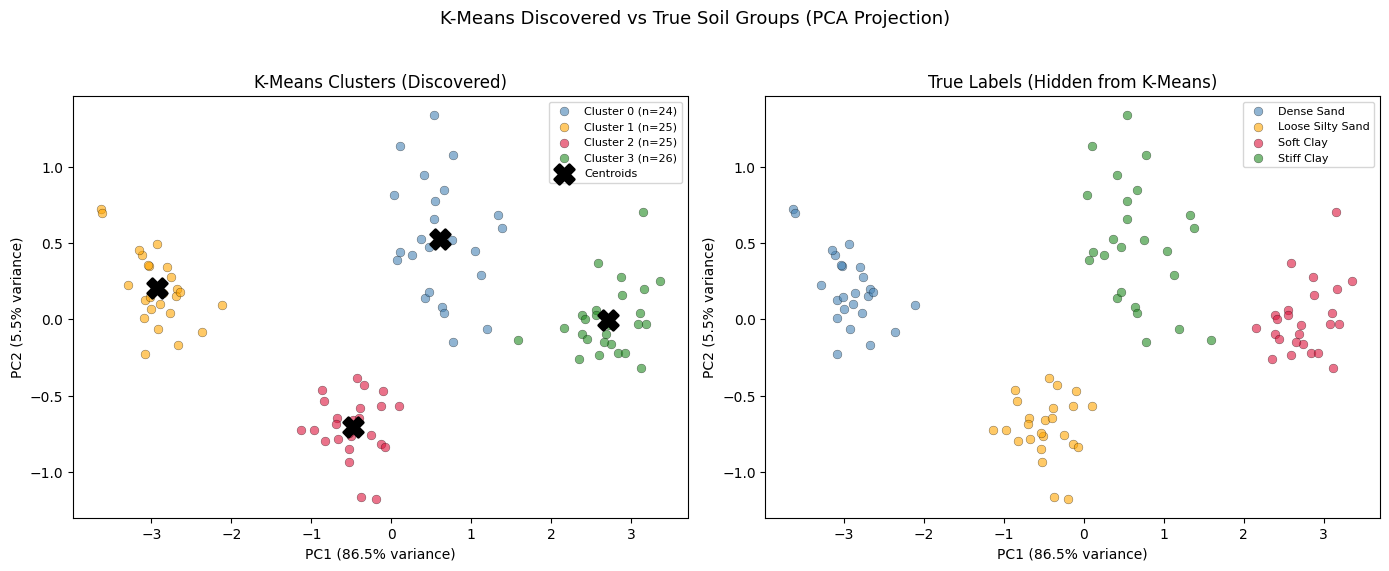

PCA captures 91.9% of total variance in 2D.
K-Means successfully recovers the 4 soil groups without any labels!


In [7]:
# ─────────────────────────────────────────────────────
# PCA VISUALIZATION OF CLUSTERS
# ─────────────────────────────────────────────────────

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Transform centroids too
centroids_pca = pca.transform(km.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

cluster_colors = ['steelblue', 'orange', 'crimson', 'forestgreen']

# Plot 1: K-Means clusters
for c in range(4):
    mask = clusters == c
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c=cluster_colors[c],
                    alpha=0.6, edgecolors='k', linewidth=0.3, s=40,
                    label=f'Cluster {c} (n={mask.sum()})')
axes[0].scatter(centroids_pca[:, 0], centroids_pca[:, 1],
                c='black', marker='X', s=200, linewidths=2, label='Centroids')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
axes[0].set_title('K-Means Clusters (Discovered)')
axes[0].legend(fontsize=8)

# Plot 2: True labels (for comparison)
for g in range(4):
    mask = true_labels == g
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], c=cluster_colors[g],
                    alpha=0.6, edgecolors='k', linewidth=0.3, s=40,
                    label=true_names[g])
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
axes[1].set_title('True Labels (Hidden from K-Means)')
axes[1].legend(fontsize=8)

plt.suptitle('K-Means Discovered vs True Soil Groups (PCA Projection)', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()
print(f"PCA captures {pca.explained_variance_ratio_.sum():.1%} of total variance in 2D.")
print("K-Means successfully recovers the 4 soil groups without any labels!")

---

## Part 7: Interpret Clusters as Soil Groups

The real value: what do these clusters **mean** geotechnically? We examine the centroid properties to assign soil type names.

In [8]:
# ─────────────────────────────────────────────────────
# INTERPRET CLUSTERS — Centroid Analysis
# ─────────────────────────────────────────────────────

# Unscale centroids back to original units
centroids_original = scaler.inverse_transform(km.cluster_centers_)
centroid_df = pd.DataFrame(centroids_original, columns=df.columns[:-1])

print("Cluster Centroids (original scale):")
print(centroid_df.round(1).to_string())

# Summary per cluster
print("\n" + "─" * 70)
print("Cluster Interpretation:")
print("─" * 70)
for c in range(4):
    row = centroid_df.iloc[c]
    n = row['N_value']
    wc = row['water_content']
    fc = row['fines_content']
    vr = row['void_ratio']
    uw = row['unit_weight']
    
    # Automatic interpretation
    if n > 25 and fc < 15:
        name = "Dense Sand"
    elif n < 8 and fc > 60:
        name = "Soft Clay"
    elif fc > 50:
        name = "Stiff Clay"
    else:
        name = "Loose Silty Sand"
    
    print(f"\n  Cluster {c}: {name}")
    print(f"    N={n:.0f}, WC={wc:.0f}%, Fines={fc:.0f}%, e={vr:.2f}, gamma={uw:.1f} kN/m3")

Cluster Centroids (original scale):
   N_value  water_content  fines_content  void_ratio  unit_weight
0     17.6           29.0           63.8         0.8         16.7
1     32.0           11.5            7.9         0.4         19.5
2     12.1           23.3           28.9         0.6         17.5
3      3.7           42.2           75.2         1.1         15.5

──────────────────────────────────────────────────────────────────────
Cluster Interpretation:
──────────────────────────────────────────────────────────────────────

  Cluster 0: Stiff Clay
    N=18, WC=29%, Fines=64%, e=0.82, gamma=16.7 kN/m3

  Cluster 1: Dense Sand
    N=32, WC=11%, Fines=8%, e=0.45, gamma=19.5 kN/m3

  Cluster 2: Loose Silty Sand
    N=12, WC=23%, Fines=29%, e=0.64, gamma=17.5 kN/m3

  Cluster 3: Soft Clay
    N=4, WC=42%, Fines=75%, e=1.14, gamma=15.5 kN/m3


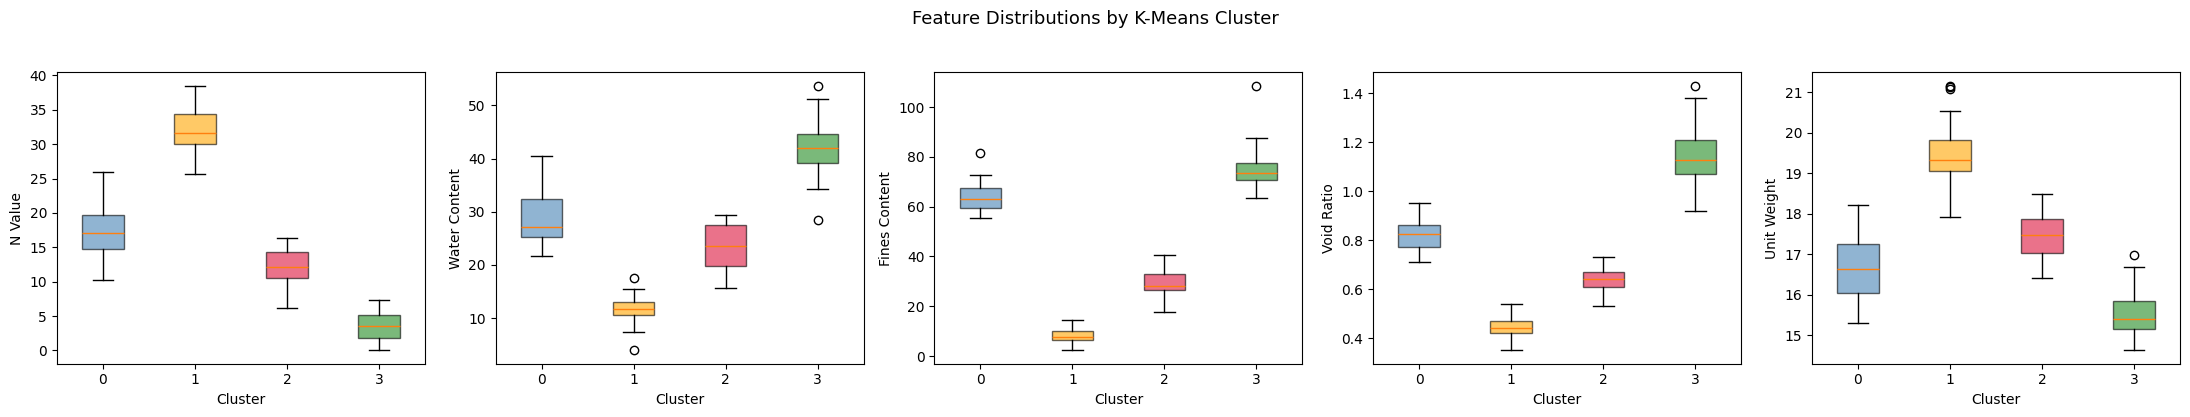

Each cluster has distinct property ranges — confirming meaningful soil groups.


In [9]:
# ─────────────────────────────────────────────────────
# CLUSTER PROPERTY DISTRIBUTIONS
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, col in zip(axes, df.columns[:-1]):
    data_by_cluster = [df[df['cluster'] == c][col] for c in range(4)]
    bp = ax.boxplot(data_by_cluster, patch_artist=True)
    for patch, color in zip(bp['boxes'], cluster_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    ax.set_xlabel('Cluster')
    ax.set_ylabel(col.replace('_', ' ').title())
    ax.set_xticklabels(['0', '1', '2', '3'])

plt.suptitle('Feature Distributions by K-Means Cluster', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()
print("Each cluster has distinct property ranges — confirming meaningful soil groups.")

---

## Part 8: Silhouette Analysis — Cluster Quality per Sample

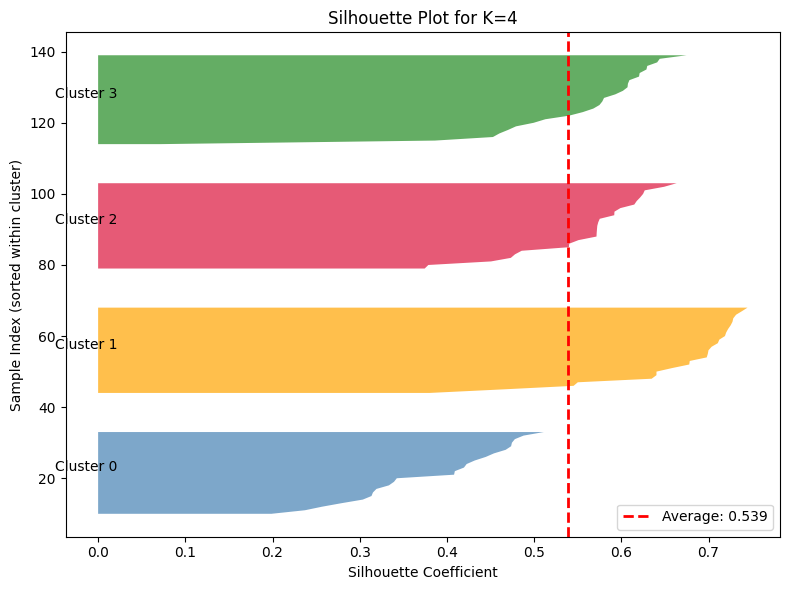

Silhouette score ranges from -1 to 1:
  +1: Sample is far from other clusters (well-assigned)
   0: Sample is on the boundary between clusters
  -1: Sample is likely in the wrong cluster

Our average: 0.539 — good clustering quality.


In [10]:
# ─────────────────────────────────────────────────────
# SILHOUETTE PLOT
# ─────────────────────────────────────────────────────

sil_values = silhouette_samples(X_scaled, clusters)
avg_sil = silhouette_score(X_scaled, clusters)

fig, ax = plt.subplots(figsize=(8, 6))

y_lower = 10
for c in range(4):
    cluster_sil = sil_values[clusters == c]
    cluster_sil.sort()
    y_upper = y_lower + len(cluster_sil)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_sil,
                     facecolor=cluster_colors[c], alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * len(cluster_sil), f'Cluster {c}', fontsize=10)
    y_lower = y_upper + 10

ax.axvline(x=avg_sil, color='red', linestyle='--', linewidth=2,
           label=f'Average: {avg_sil:.3f}')
ax.set_xlabel('Silhouette Coefficient')
ax.set_ylabel('Sample Index (sorted within cluster)')
ax.set_title('Silhouette Plot for K=4')
ax.legend()
plt.tight_layout()
plt.show()

print("Silhouette score ranges from -1 to 1:")
print("  +1: Sample is far from other clusters (well-assigned)")
print("   0: Sample is on the boundary between clusters")
print("  -1: Sample is likely in the wrong cluster")
print(f"\nOur average: {avg_sil:.3f} — good clustering quality.")

---

## Part 9: Assign New Soil Samples to Clusters

In [11]:
# ─────────────────────────────────────────────────────
# PREDICT CLUSTER FOR NEW SAMPLES
# ─────────────────────────────────────────────────────

new_samples = pd.DataFrame({
    'N_value': [30, 6, 14, 20],
    'water_content': [10, 45, 24, 32],
    'fines_content': [5, 80, 30, 58],
    'void_ratio': [0.42, 1.15, 0.68, 0.80],
    'unit_weight': [20.0, 15.2, 17.8, 16.8]
})

new_scaled = scaler.transform(new_samples)
new_clusters = km.predict(new_scaled)

print("New Sample Cluster Assignments:")
print(f"{'#':>3} {'N':>5} {'WC':>5} {'Fines':>6} {'e':>5} {'gamma':>6} {'Cluster':>8}")
print("─" * 42)
for i, (_, row) in enumerate(new_samples.iterrows()):
    print(f"{i+1:3d} {row['N_value']:5.0f} {row['water_content']:4.0f}% "
          f"{row['fines_content']:5.0f}% {row['void_ratio']:5.2f} "
          f"{row['unit_weight']:5.1f} {new_clusters[i]:>8d}")

print("\nNew samples are assigned to the nearest existing cluster centroid.")

New Sample Cluster Assignments:
  #     N    WC  Fines     e  gamma  Cluster
──────────────────────────────────────────
  1    30   10%     5%  0.42  20.0        1
  2     6   45%    80%  1.15  15.2        3
  3    14   24%    30%  0.68  17.8        2
  4    20   32%    58%  0.80  16.8        0

New samples are assigned to the nearest existing cluster centroid.


---

## Practice Exercises

### Exercise 1: Wrong K
Run K-Means with K=2 and K=6. Visualize with PCA. How do the clusters change? What happens when K is too small or too large?

### Exercise 2: Initialization Sensitivity
Run K-Means 5 times with `n_init=1` (single random start). Do you get different results each time? Compare with `n_init=10`. Why does `n_init` matter?

### Exercise 3: Feature Importance
Run K-Means with only 2 features at a time. Which pair of features gives the best silhouette score? Which features are most important for distinguishing soil groups?

In [12]:
# EXERCISE 1: K=2 and K=6
# km2 = KMeans(n_clusters=2, n_init=10, random_state=46).fit(X_scaled)
# km6 = KMeans(n_clusters=6, n_init=10, random_state=46).fit(X_scaled)
# print(f"K=2 silhouette: {silhouette_score(X_scaled, km2.labels_):.3f}")
# print(f"K=6 silhouette: {silhouette_score(X_scaled, km6.labels_):.3f}")

In [13]:
# EXERCISE 2: Initialization sensitivity
# for seed in range(5):
#     km_tmp = KMeans(n_clusters=4, n_init=1, random_state=seed).fit(X_scaled)
#     print(f"Seed {seed}: inertia={km_tmp.inertia_:.1f}")

In [14]:
# EXERCISE 3: Feature pair analysis
# from itertools import combinations
# for f1, f2 in combinations(df.columns[:-1], 2):
#     X_pair = scaler.fit_transform(df[[f1, f2]])
#     km_tmp = KMeans(n_clusters=4, n_init=10, random_state=46).fit(X_pair)
#     sil = silhouette_score(X_pair, km_tmp.labels_)
#     print(f"{f1:18s} + {f2:18s}: Silhouette = {sil:.3f}")

---

## Key Takeaways

1. **K-Means is unsupervised** — it discovers natural groups in data without labels. This is perfect for exploring site investigation data where soil classifications are unknown.

2. **The elbow method and silhouette score** help choose the right K. Look for the bend in the inertia curve and the peak in silhouette score.

3. **Always scale features** before K-Means. Like SVM, it uses distances, so unscaled features with larger ranges dominate the clustering.

4. **Interpret clusters geotechnically** by examining centroid properties. Each cluster should correspond to a recognizable soil type with distinct engineering behavior.

5. **PCA visualization** lets you see high-dimensional clusters in 2D. It is the standard way to present clustering results.

---

## How This Connects to ML

| Today's Concept | ML Application |
|----------------|----------------|
| Unsupervised learning | Learning without labels |
| K-Means algorithm | Most popular clustering method |
| Centroids | Cluster representatives |
| Elbow method | Model selection for K |
| Silhouette score | Internal cluster validation |
| PCA | Dimensionality reduction for visualization |
| Feature scaling | Essential preprocessing for distance-based methods |
| Cluster interpretation | Making ML results actionable |

---

*Day 046 of 100 — K-Means discovers soil groups that nature created!*